In [10]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import fsolve
from matplotlib.animation import FuncAnimation, PillowWriter

TEAL      = "#00A39B"   
DARK_TEAL = "#006661"   # axes, titles
CORAL     = "#E8633A"   
BLUE      = "#0A4D9E"
SLATE     = "#5F6B7A"

# Math needed to simulate diagram

# ?leave between 0 and 1 
r = 0.5
# carrying capacity
K = 10
# constant (cost)
c = 1
# discount factor
a = 0.3

#xmax f'(xmax) = 1
xmax = K/2

# f(x) =dx/dt=x+rx (1-x/K) concave?
def f(x):
    return x + r*x*(1 - x/K)
    
# f‘ (x) =1+ r - (2rx/K) should be decreasing
def f_deriv(x):
    return 1 + r - (2*r*x/K)

# add the discounting factor to f'(x)
def discount_f_deriv(x):
    return a*(1 + r - (2*r*x/K))

# g(x) = c/(x+1)
def g(x):
    return c/(x + 1)

# M'(x) = p - g(x)
def M_deriv(x, p):
    return p - g(x)

# Second curve: M'(x)/ Μ'[f(x)] = p - g(x)/p-g(f(x))
def second_curve(x, p):
    return M_deriv(x, p) / M_deriv(f(x), p)

#Can we assume that x̄ = f(x̄) if clarke says 0 <=x <= x̄ = f(x̄)???
def natural_equilibrium(x):
    return f(x) - x
# the equilibrium should be equal to K
x_equilib = K #fsolve(natural_equilibrium, 5)[0]

# prices p
# p >= g(0) high price
p_high = g(0) + 0.2
# p = g(0) to depict intermediate price
p_intermediate = g(0)

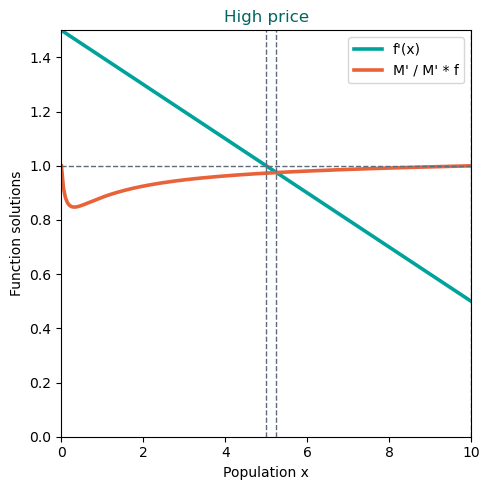

/var/folders/k0/nwv5074129n7c165jjk349xm0000gn/T/ipykernel_66957/806610938.py:47: RuntimeWarning: divide by zero encountered in divide
  return M_deriv(x, p) / M_deriv(f(x), p)
/var/folders/k0/nwv5074129n7c165jjk349xm0000gn/T/ipykernel_66957/806610938.py:47: RuntimeWarning: invalid value encountered in divide
  return M_deriv(x, p) / M_deriv(f(x), p)


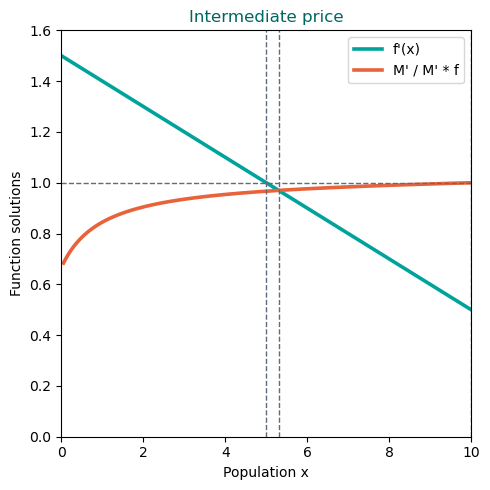

In [9]:
#Simulating model

# from notebook W2 stock, flows & feedback
# high price
x = np.linspace(0, 30, 600)
p = p_high

# ξ  f'(ξ) = M'(x)/ Μ'[f(x)]
def xi_func(x):
        return f_deriv(x) - second_curve(x, p)

xi = fsolve(xi_func, K/4)[0]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, f_deriv(x), color=TEAL, lw=2.6, label="f'(x)")
ax.plot(x, second_curve(x, p), color=CORAL, lw=2.6, label="M' / M' * f")

ax.axvline(xmax, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(xi, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(x_equilib, color=SLATE, linestyle = "--", lw = 1)
ax.axhline(1, color=SLATE, linestyle = "--", lw = 1)
ax.set_xlabel('Population x'); ax.set_ylabel('Function solutions')
ax.set_title('High price', color=DARK_TEAL); ax.set_xlim(0, 10); ax.set_ylim(0, 1.5)
ax.legend(); plt.tight_layout(); plt.show()

# intermediate price
p = p_intermediate

# ξ  f'(ξ) = M'(x)/ Μ'[f(x)]
def xi_func(x):
        return f_deriv(x) - second_curve(x, p)
    
xi = fsolve(xi_func, K/4)[0]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, f_deriv(x), color=TEAL, lw=2.6, label="f'(x)")
ax.plot(x, second_curve(x, p), color=CORAL, lw=2.6, label="M' / M' * f")

ax.axvline(xmax, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(xi, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(x_equilib, color=SLATE, linestyle = "--", lw = 1)
ax.axhline(1, color=SLATE, linestyle = "--", lw = 1)
ax.set_xlabel('Population x'); ax.set_ylabel('Function solutions')
ax.set_title('Intermediate price', color=DARK_TEAL); ax.set_xlim(0, 10); ax.set_ylim(0, 1.6)
ax.legend(); plt.tight_layout(); plt.show()

/var/folders/k0/nwv5074129n7c165jjk349xm0000gn/T/ipykernel_66957/1749572240.py:48: RuntimeWarning: divide by zero encountered in divide
  return M_deriv(x, p) / M_deriv(f(x), p)
/var/folders/k0/nwv5074129n7c165jjk349xm0000gn/T/ipykernel_66957/1749572240.py:48: RuntimeWarning: invalid value encountered in divide
  return M_deriv(x, p) / M_deriv(f(x), p)


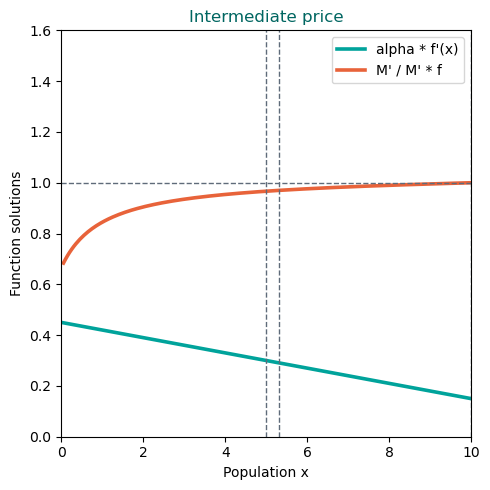

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, discount_f_deriv(x), color=TEAL, lw=2.6, label="alpha * f'(x)")
ax.plot(x, second_curve(x, p), color=CORAL, lw=2.6, label="M' / M' * f")

ax.axvline(xmax, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(xi, color=SLATE, linestyle = "--", lw = 1)
ax.axvline(x_equilib, color=SLATE, linestyle = "--", lw = 1)
ax.axhline(1, color=SLATE, linestyle = "--", lw = 1)
ax.set_xlabel('Population x'); ax.set_ylabel('Function solutions')
ax.set_title('Intermediate price', color=DARK_TEAL); ax.set_xlim(0, 10); ax.set_ylim(0, 1.6)
ax.legend(); plt.tight_layout(); plt.show()